In [14]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.precision", 3)
plt.rcParams["figure.figsize"] = (7, 4)


def check(label, test, hint=""):
    """Self-check helper: prints ✅ or ❌ (with a hint)."""
    try:
        ok = bool(test())
    except Exception as e:
        ok, hint = False, f"{hint}  (error: {type(e).__name__}: {e})"
    print(("✅ " if ok else "❌ ") + label + ("" if ok else f"\n   hint: {hint}"))

print("Ready!")

Ready!


In [ ]:

from house import House

simulator = House(num_of_houses=500)

simulator.set_area_attributes(max_area=2500, min_area=300, area_std=300, average_area=900)
simulator.set_bedroom_attributes(sq_ft_per_bedroom=350, bedroom_noise_std=0.7, min_bedrooms=1, max_bedrooms=6)
simulator.set_age_attributes(min_age=0, max_age=120)
simulator.set_distance_attributes(min_distance=1, max_distance=20)
simulator.set_price_attributes(
    base_price=300,
    price_per_sq_ft=0.45,
    price_per_bedroom=25,
    price_reduction_per_year=0.8,
    price_reduction_per_mile=18,
    price_noise_std=0,
    price_noise_mean=45
)

df = simulator.to_dataframe(add_random_noise=True, feature_noise_mean=0, feature_noise_std=1)


print(df.head())
# df.shape

     area  bedrooms    age  distance  random_noise   price
0   991.0       3.0   93.0      15.7          0.30  508.95
1   588.0       1.0   53.0       9.3         -1.04  424.80
2  1125.0       4.0  103.0      17.3          0.75  557.45
3  1182.0       4.0   84.0      14.2          0.94  654.10
4   315.0       1.0   11.0       2.8         -1.95  452.55


In [16]:
df.describe()

,area,bedrooms,age,distance,random_noise,price
count,500.000,500.000,500.000,500.000,500.000,500.000
mean,897.246,2.638,59.492,10.418,-0.013,579.600
std,285.285,1.329,34.416,5.450,0.960,201.462
min,300.000,1.000,1.000,1.100,-2.570,76.200
25%,699.750,2.000,28.000,5.475,-0.670,434.275
50%,901.000,3.000,60.000,10.500,0.005,577.850
75%,1076.250,3.000,90.000,15.200,0.590,718.913
max,1774.000,6.000,120.000,20.000,2.910,1238.500


In [17]:
# print(df.head())
# print(df.shape)
# print(df.dtypes)
# print(df.isnull().sum())
print(df.duplicated().sum())

1


In [18]:
df.loc[df["bedrooms"]].idxmin()






area            4
bedrooms        1
age             4
distance        4
random_noise    4
price           5
dtype: int64

In [19]:
df.describe()

,area,bedrooms,age,distance,random_noise,price
count,500.000,500.000,500.000,500.000,500.000,500.000
mean,897.246,2.638,59.492,10.418,-0.013,579.600
std,285.285,1.329,34.416,5.450,0.960,201.462
min,300.000,1.000,1.000,1.100,-2.570,76.200
25%,699.750,2.000,28.000,5.475,-0.670,434.275
50%,901.000,3.000,60.000,10.500,0.005,577.850
75%,1076.250,3.000,90.000,15.200,0.590,718.913
max,1774.000,6.000,120.000,20.000,2.910,1238.500


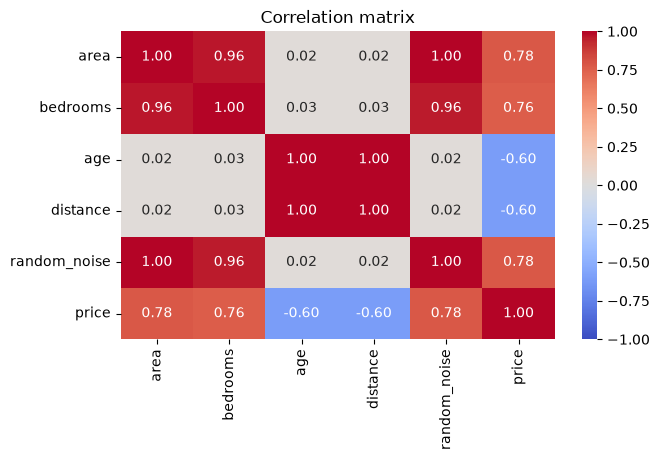

price           1.000
area            0.781
random_noise    0.779
bedrooms        0.761
distance       -0.604
age            -0.604
Name: price, dtype: float64

In [20]:

corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.show()

corr["price"].sort_values(ascending=False)